# 01 — Chargement et Exploration du Dataset NASA CMAPSS

## Cellule 1 — Téléchargement du dataset brut

In [1]:

import urllib.request
import os

# Créer les dossiers du projet
os.makedirs('../data/raw',       exist_ok=True)
os.makedirs('../data/processed', exist_ok=True)

# URL directe depuis GitHub 
URL    = 'https://raw.githubusercontent.com/hankroark/Turbofan-Engine-Degradation/master/CMAPSSData/train_FD001.txt'
CHEMIN = '../data/raw/train_FD001.txt'

if not os.path.exists(CHEMIN):
    print('Téléchargement en cours...')
    urllib.request.urlretrieve(URL, CHEMIN)
    taille = os.path.getsize(CHEMIN) / 1024
    print(f'OK — fichier sauvegardé ({taille:.0f} KB) : {CHEMIN}')
else:
    taille = os.path.getsize(CHEMIN) / 1024
    print(f'Déjà présent ({taille:.0f} KB) : {CHEMIN}')

# Aperçu brut du fichier avant tout traitement
print()
print('=== 3 PREMIÈRES LIGNES BRUTES DU FICHIER ===')
with open(CHEMIN, 'r') as f:
    for i, ligne in enumerate(f):
        if i == 3: break
        print(f'Ligne {i+1}: {ligne.strip()}')
print()
print('Observation : valeurs séparées par des espaces, pas de noms de colonnes')

Déjà présent (3433 KB) : ../data/raw/train_FD001.txt

=== 3 PREMIÈRES LIGNES BRUTES DU FICHIER ===
Ligne 1: 1 1 -0.0007 -0.0004 100.0 518.67 641.82 1589.70 1400.60 14.62 21.61 554.36 2388.06 9046.19 1.30 47.47 521.66 2388.02 8138.62 8.4195 0.03 392 2388 100.00 39.06 23.4190
Ligne 2: 1 2 0.0019 -0.0003 100.0 518.67 642.15 1591.82 1403.14 14.62 21.61 553.75 2388.04 9044.07 1.30 47.49 522.28 2388.07 8131.49 8.4318 0.03 392 2388 100.00 39.00 23.4236
Ligne 3: 1 3 -0.0043 0.0003 100.0 518.67 642.35 1587.99 1404.20 14.62 21.61 554.26 2388.08 9052.94 1.30 47.27 522.42 2388.03 8133.23 8.4178 0.03 390 2388 100.00 38.95 23.3442

Observation : valeurs séparées par des espaces, pas de noms de colonnes


## Cellule 2 — Import des bibliothèques

In [2]:

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import warnings

warnings.filterwarnings('ignore')

plt.rcParams['figure.figsize']    = (14, 5)
plt.rcParams['font.size']         = 11
plt.rcParams['axes.spines.top']   = False
plt.rcParams['axes.spines.right'] = False
sns.set_palette('husl')

print(f'pandas  : {pd.__version__}')
print(f'numpy   : {np.__version__}')
print(f'seaborn : {sns.__version__}')
print('Prêt !')

pandas  : 2.2.3
numpy   : 2.1.3
seaborn : 0.13.2
Prêt !


## Cellule 3 — Charger les données SANS noms de colonnes

On charge d'abord **sans noms** pour voir la structure réelle du fichier.
Cela permet de comprendre le format avant de nommer quoi que ce soit.

In [3]:

df_brut = pd.read_csv(CHEMIN, sep=r'\s+', header=None)
print('=== FICHIER BRUT CHARGÉ ===')
print(f'Lignes   : {df_brut.shape[0]:,}')
print(f'Colonnes : {df_brut.shape[1]}')
print()
print('Aperçu (colonnes nommées 0, 1, 2...) :')
print(df_brut.head(5).to_string())
print()
print('Dernières lignes :')
print(df_brut.tail(3).to_string())
print()
print('Valeurs manquantes par colonne :')
print(df_brut.isnull().sum().to_string())
print()
print(f'Colonne 0 = identifiant moteur : valeurs de {df_brut[0].min()} à {df_brut[0].max()}')
print(f'Colonne 1 = numéro cycle       : commence à {df_brut[1].min()}')
print(f'Les 2 dernières colonnes ont uniquement des NaN → à supprimer')

=== FICHIER BRUT CHARGÉ ===
Lignes   : 20,631
Colonnes : 26

Aperçu (colonnes nommées 0, 1, 2...) :
   0   1       2       3      4       5       6        7        8      9      10      11       12       13   14     15      16       17       18      19    20   21    22     23     24       25
0   1   1 -0.0007 -0.0004  100.0  518.67  641.82  1589.70  1400.60  14.62  21.61  554.36  2388.06  9046.19  1.3  47.47  521.66  2388.02  8138.62  8.4195  0.03  392  2388  100.0  39.06  23.4190
1   1   2  0.0019 -0.0003  100.0  518.67  642.15  1591.82  1403.14  14.62  21.61  553.75  2388.04  9044.07  1.3  47.49  522.28  2388.07  8131.49  8.4318  0.03  392  2388  100.0  39.00  23.4236
2   1   3 -0.0043  0.0003  100.0  518.67  642.35  1587.99  1404.20  14.62  21.61  554.26  2388.08  9052.94  1.3  47.27  522.42  2388.03  8133.23  8.4178  0.03  390  2388  100.0  38.95  23.3442
3   1   4  0.0007  0.0000  100.0  518.67  642.35  1582.79  1401.87  14.62  21.61  554.45  2388.11  9049.48  1.3  47.13  522.86  

## Cellule 4 — Nommer les colonnes et supprimer les colonnes vides

Maintenant qu'on a vu la structure, on nomme les colonnes selon la documentation NASA.
On supprime aussi les 2 dernières colonnes qui sont vides (artefact du fichier).

In [4]:

# Noms officiels selon la documentation NASA CMAPSS
NOMS_COLONNES = [
    'unit_id',    # identifiant du moteur (1 à 100)
    'cycle',      # numéro du cycle de vol (commence à 1)
    'op_set_1',   # réglage opérationnel 1 (conditions de vol)
    'op_set_2',   # réglage opérationnel 2
    'op_set_3',   # réglage opérationnel 3
    's1',         # température totale entrée ventilateur (°R)
    's2',         # pression totale entrée ventilateur
    's3',         # vitesse flux physique ventilateur
    's4',         # température totale sortie compresseur HP
    's5',         # pression physique totale sortie compresseur HP
    's6',         # ratio air/carburant
    's7',         # pression totale sortie compresseur HP
    's8',         # température physique totale sortie compresseur HP
    's9',         # vitesse physique compresseur HP
    's10',        # pression statique sortie turbine HP
    's11',        # rapport de pression turbine HP
    's12',        # température sortie turbine HP
    's13',        # rapport de pression turbine BP
    's14',        # rapport de bypass ventilateur
    's15',        # débit massique entrée ventilateur
    's16',        # rapport bypass corrigé
    's17',        # régime ventilateur corrigé
    's18',        # vitesse moteur
    's19',        # rapport pression moteur
    's20',        # débit huile HP
    's21',        # température huile HP
    'vide_1',     # colonne vide (artefact du fichier)
    'vide_2',     # colonne vide (artefact du fichier)
]

# Recharger avec les bons noms
df = pd.read_csv(CHEMIN, sep=r'\s+', header=None, names=NOMS_COLONNES)

# Supprimer les 2 colonnes vides
df = df.drop(columns=['vide_1', 'vide_2'])

# Liste de tous les capteurs pour usage futur
CAPTEURS_TOUS = [f's{i}' for i in range(1, 22)]

print('Dataset nommé et nettoyé !')
print(f'Dimensions finales : {df.shape[0]:,} lignes × {df.shape[1]} colonnes')
print()
print('Colonnes disponibles :')
print(list(df.columns))
print()
df.head()

Dataset nommé et nettoyé !
Dimensions finales : 20,631 lignes × 26 colonnes

Colonnes disponibles :
['unit_id', 'cycle', 'op_set_1', 'op_set_2', 'op_set_3', 's1', 's2', 's3', 's4', 's5', 's6', 's7', 's8', 's9', 's10', 's11', 's12', 's13', 's14', 's15', 's16', 's17', 's18', 's19', 's20', 's21']



,unit_id,cycle,op_set_1,op_set_2,op_set_3,s1,s2,s3,s4,s5,...,s12,s13,s14,s15,s16,s17,s18,s19,s20,s21
0,1,1,-0.0007,-0.0004,100.0,518.67,641.82,1589.70,1400.60,14.62,...,521.66,2388.02,8138.62,8.4195,0.03,392,2388,100.0,39.06,23.4190
1,1,2,0.0019,-0.0003,100.0,518.67,642.15,1591.82,1403.14,14.62,...,522.28,2388.07,8131.49,8.4318,0.03,392,2388,100.0,39.00,23.4236
2,1,3,-0.0043,0.0003,100.0,518.67,642.35,1587.99,1404.20,14.62,...,522.42,2388.03,8133.23,8.4178,0.03,390,2388,100.0,38.95,23.3442
3,1,4,0.0007,0.0000,100.0,518.67,642.35,1582.79,1401.87,14.62,...,522.86,2388.08,8133.83,8.3682,0.03,392,2388,100.0,38.88,23.3739
4,1,5,-0.0019,-0.0002,100.0,518.67,642.37,1582.85,1406.22,14.62,...,522.19,2388.04,8133.80,8.4294,0.03,393,2388,100.0,38.90,23.4044


## Cellule 5 — Statistiques de base : répondre à 4 questions

Avant toute modélisation, on répond à ces questions fondamentales :
1. Combien de moteurs ?
2. Quelle est la durée de vie typique ?
3. Y a-t-il des valeurs manquantes ?
4. Les types de données sont-ils corrects ?

In [5]:

print('=' * 55)
print('  ANALYSE DE BASE DU DATASET NASA CMAPSS')
print('=' * 55)

# 1. Combien de moteurs
nb_moteurs = df['unit_id'].nunique()
print(f'\n1. Nombre de moteurs : {nb_moteurs}')

# 2. Durée de vie
duree_vie = df.groupby('unit_id')['cycle'].max()
print(f'\n2. Durée de vie (cycles avant panne) :')
print(f'   Minimum  : {duree_vie.min()} cycles')
print(f'   Maximum  : {duree_vie.max()} cycles')
print(f'   Moyenne  : {duree_vie.mean():.1f} cycles')
print(f'   Médiane  : {duree_vie.median():.0f} cycles')
print(f'   Std      : {duree_vie.std():.1f} cycles')

# 3. Valeurs manquantes
print(f'\n3. Valeurs manquantes : {df.isnull().sum().sum()} au total')
if df.isnull().sum().sum() == 0:
    print('   Aucune — dataset complet ✓')

# 4. Types
print(f'\n4. Types de données :')
print(f'   int64   : {list(df.select_dtypes(include="int64").columns)}')
print(f'   int64 : {len(df.select_dtypes(include="int64").columns)} colonnes')
print(f'   float64   : {list(df.select_dtypes(include="float64").columns)}')
print(f'   float64 : {len(df.select_dtypes(include="float64").columns)} colonnes')

# 5. Zoom moteur 1
print(f'\n5. Zoom sur le moteur n°1 :')
m1 = df[df['unit_id'] == 1]
print(f'   Cycles : {m1["cycle"].min()} → {m1["cycle"].max()}  (panne au cycle {m1["cycle"].max()})')
print(f'   Lignes : {len(m1)}  (1 ligne = 1 vol = 1 mesure)')
print()
print('Statistiques globales :')
df.describe().round(3)

  ANALYSE DE BASE DU DATASET NASA CMAPSS

1. Nombre de moteurs : 100

2. Durée de vie (cycles avant panne) :
   Minimum  : 128 cycles
   Maximum  : 362 cycles
   Moyenne  : 206.3 cycles
   Médiane  : 199 cycles
   Std      : 46.3 cycles

3. Valeurs manquantes : 0 au total
   Aucune — dataset complet ✓

4. Types de données :
   int64   : ['unit_id', 'cycle', 's17', 's18']
   int64 : 4 colonnes
   float64   : ['op_set_1', 'op_set_2', 'op_set_3', 's1', 's2', 's3', 's4', 's5', 's6', 's7', 's8', 's9', 's10', 's11', 's12', 's13', 's14', 's15', 's16', 's19', 's20', 's21']
   float64 : 22 colonnes

5. Zoom sur le moteur n°1 :
   Cycles : 1 → 192  (panne au cycle 192)
   Lignes : 192  (1 ligne = 1 vol = 1 mesure)

Statistiques globales :


,unit_id,cycle,op_set_1,op_set_2,op_set_3,s1,s2,s3,s4,s5,...,s12,s13,s14,s15,s16,s17,s18,s19,s20,s21
count,20631.000,20631.000,20631.000,20631.000,20631.0,20631.00,20631.000,20631.000,20631.000,20631.00,...,20631.000,20631.000,20631.000,20631.000,20631.00,20631.000,20631.0,20631.0,20631.000,20631.000
mean,51.507,108.808,-0.000,0.000,100.0,518.67,642.681,1590.523,1408.934,14.62,...,521.413,2388.096,8143.753,8.442,0.03,393.211,2388.0,100.0,38.816,23.290
std,29.228,68.881,0.002,0.000,0.0,0.00,0.500,6.131,9.001,0.00,...,0.738,0.072,19.076,0.038,0.00,1.549,0.0,0.0,0.181,0.108
min,1.000,1.000,-0.009,-0.001,100.0,518.67,641.210,1571.040,1382.250,14.62,...,518.690,2387.880,8099.940,8.325,0.03,388.000,2388.0,100.0,38.140,22.894
25%,26.000,52.000,-0.002,-0.000,100.0,518.67,642.325,1586.260,1402.360,14.62,...,520.960,2388.040,8133.245,8.415,0.03,392.000,2388.0,100.0,38.700,23.222
50%,52.000,104.000,0.000,0.000,100.0,518.67,642.640,1590.100,1408.040,14.62,...,521.480,2388.090,8140.540,8.439,0.03,393.000,2388.0,100.0,38.830,23.298
75%,77.000,156.000,0.002,0.000,100.0,518.67,643.000,1594.380,1414.555,14.62,...,521.950,2388.140,8148.310,8.466,0.03,394.000,2388.0,100.0,38.950,23.367
max,100.000,362.000,0.009,0.001,100.0,518.67,644.530,1616.910,1441.490,14.62,...,523.380,2388.560,8293.720,8.585,0.03,400.000,2388.0,100.0,39.430,23.618


## Cellule 6 — Calculer le RUL 

**RUL = Remaining Useful Life = cycles restants avant la panne**


Tu vas faire le calcul en 3 étapes logiques.
Comprends bien chaque ligne — c'est la variable la plus importante du projet.

In [6]:

# ÉTAPE 1 : Pour chaque moteur, trouver son cycle de panne (cycle maximum)
cycle_panne_par_moteur = df.groupby('unit_id')['cycle'].max()
print('Cycle de panne des 5 premiers moteurs :')
print(cycle_panne_par_moteur.head().to_string())

# ÉTAPE 2 : Ajouter cette information à chaque ligne du dataset( bch na3mlou comparaison fy cycle maximum aly mawjoud vl cycle aly mawjoud fy ligne hka)
cycle_panne_df = cycle_panne_par_moteur.reset_index()
cycle_panne_df.columns = ['unit_id', 'cycle_max']
df = df.merge(cycle_panne_df, on='unit_id', how='left')

print()
print('Après merge — vérification sur les premières lignes :')
print(df[['unit_id', 'cycle', 'cycle_max']].head(5).to_string(index=False))

# ÉTAPE 3 : Calculer le RUL = cycle_max - cycle_actuel
# Exemple : moteur dure 192 cycles, il est au cycle 150 → RUL = 192 - 150 = 42
df['RUL'] = df['cycle_max'] - df['cycle']
df = df.drop(columns=['cycle_max'])  # plus besoin

print()
print('RUL calculé ! Vérification moteur n°1 :')
m1 = df[df['unit_id'] == 1][['unit_id', 'cycle', 'RUL']]
print('Début :')
print(m1.head(4).to_string(index=False))
print('Fin (avant panne) :')
print(m1.tail(4).to_string(index=False))
print()
print('Statistiques du RUL :')
print(df['RUL'].describe().round(1).to_string())

Cycle de panne des 5 premiers moteurs :
unit_id
1    192
2    287
3    179
4    189
5    269

Après merge — vérification sur les premières lignes :
 unit_id  cycle  cycle_max
       1      1        192
       1      2        192
       1      3        192
       1      4        192
       1      5        192

RUL calculé ! Vérification moteur n°1 :
Début :
 unit_id  cycle  RUL
       1      1  191
       1      2  190
       1      3  189
       1      4  188
Fin (avant panne) :
 unit_id  cycle  RUL
       1    189    3
       1    190    2
       1    191    1
       1    192    0

Statistiques du RUL :
count    20631.0
mean       107.8
std         68.9
min          0.0
25%         51.0
50%        103.0
75%        155.0
max        361.0


## Cellule 7 — Créer le label toi-même

On transforme le RUL continu en **classification binaire** :
- **Label 0** = machine saine (RUL > seuil)
- **Label 1** = panne imminente (RUL ≤ seuil)

Tu contrôles le seuil — change la valeur et observe l'effet sur la distribution.

Seuil choisi : 30 cycles
  Label 0 — Normal          : 17,531 lignes  (85.0%)
  Label 1 — Panne imminente :  3,100 lignes  (15.0%)



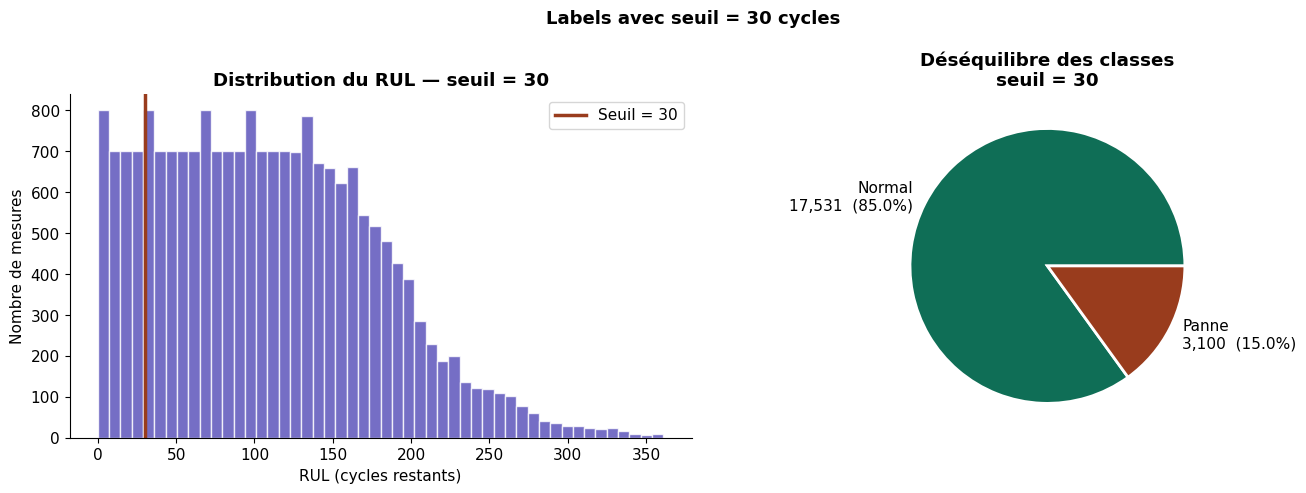

→ Déséquilibre 85%/15% — sera corrigé avec SMOTE à l'étape 2


In [7]:

# ← ce seuil on a 3 fonction(L'équilibre des classes,  Le temps de réaction industrielle)
SEUIL_PANNE = 30

# Créer le label
df['label'] = (df['RUL'] <= SEUIL_PANNE).astype(int)

# Analyser la distribution
nb_total  = len(df)
nb_normal = (df['label'] == 0).sum()
nb_panne  = (df['label'] == 1).sum()
pct_panne = nb_panne / nb_total * 100

print(f'Seuil choisi : {SEUIL_PANNE} cycles')
print(f'  Label 0 — Normal          : {nb_normal:>6,} lignes  ({100-pct_panne:.1f}%)')
print(f'  Label 1 — Panne imminente : {nb_panne:>6,} lignes  ({pct_panne:.1f}%)')
print()

# Visualisation
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

axes[0].hist(df['RUL'], bins=50, color='#534AB7', alpha=0.8, edgecolor='white')
axes[0].axvline(SEUIL_PANNE, color='#993C1D', linewidth=2.5, label=f'Seuil = {SEUIL_PANNE}')
axes[0].set_title(f'Distribution du RUL — seuil = {SEUIL_PANNE}', fontweight='bold')
axes[0].set_xlabel('RUL (cycles restants)')
axes[0].set_ylabel('Nombre de mesures')
axes[0].legend()

axes[1].pie([nb_normal, nb_panne],
    labels=[f'Normal\n{nb_normal:,}  ({100-pct_panne:.1f}%)',
            f'Panne\n{nb_panne:,}  ({pct_panne:.1f}%)'],
    colors=['#0F6E56', '#993C1D'],
    wedgeprops={'edgecolor':'white','linewidth':2})
axes[1].set_title(f'Déséquilibre des classes\nseuil = {SEUIL_PANNE}', fontweight='bold')

plt.suptitle(f'Labels avec seuil = {SEUIL_PANNE} cycles', fontsize=13, fontweight='bold')
plt.tight_layout()
plt.savefig('../data/processed/g1_labels.png', dpi=150, bbox_inches='tight')
plt.show()
print(f'→ Déséquilibre {100-pct_panne:.0f}%/{pct_panne:.0f}% — sera corrigé avec SMOTE à l\'étape 2')

## Cellule 8 — Identifier les capteurs constants (inutiles pour le ML)

Un capteur qui ne varie jamais = écart-type proche de 0.
Ces capteurs n'apportent aucune information → on les identifie maintenant,
on les supprimera au preprocessing.

Capteur    Écart-type   Statut
--------------------------------------------
s1             0.0000   ✗ CONSTANT  → sera supprimé
s2             0.5001   ✓ Variable  → utile
s3             6.1311   ✓ Variable  → utile
s4             9.0006   ✓ Variable  → utile
s5             0.0000   ✗ CONSTANT  → sera supprimé
s6             0.0014   ✗ CONSTANT  → sera supprimé
s7             0.8851   ✓ Variable  → utile
s8             0.0710   ✓ Variable  → utile
s9            22.0829   ✓ Variable  → utile
s10            0.0000   ✗ CONSTANT  → sera supprimé
s11            0.2671   ✓ Variable  → utile
s12            0.7376   ✓ Variable  → utile
s13            0.0719   ✓ Variable  → utile
s14           19.0762   ✓ Variable  → utile
s15            0.0375   ✓ Variable  → utile
s16            0.0000   ✗ CONSTANT  → sera supprimé
s17            1.5488   ✓ Variable  → utile
s18            0.0000   ✗ CONSTANT  → sera supprimé
s19            0.0000   ✗ CONSTANT  → sera supprimé
s20            0.1807   ✓ Variab

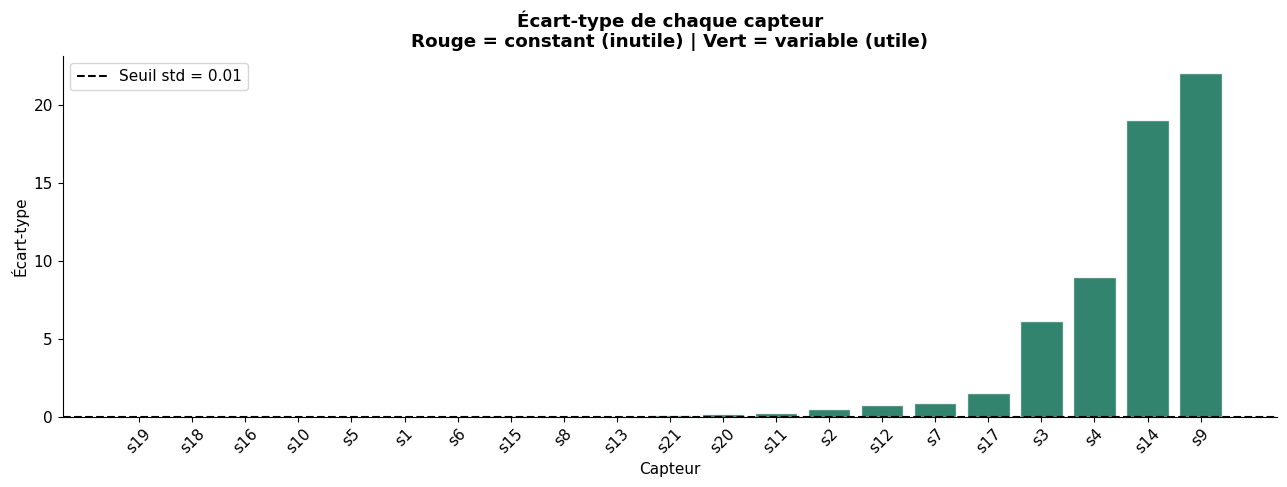

In [8]:

std_capteurs = df[CAPTEURS_TOUS].std().sort_values()

SEUIL_STD         = 0.01
CAPTEURS_INUTILES = list(std_capteurs[std_capteurs <  SEUIL_STD].index)
CAPTEURS_UTILES   = list(std_capteurs[std_capteurs >= SEUIL_STD].index)

print(f'{'Capteur':<8} {'Écart-type':>12}   Statut')
print('-' * 44)
for cap in CAPTEURS_TOUS:
    std  = std_capteurs[cap]
    stat = '✗ CONSTANT  → sera supprimé' if std < SEUIL_STD else '✓ Variable  → utile'
    print(f'{cap:<8} {std:>12.4f}   {stat}')

print()
print(f'Total   : {len(CAPTEURS_TOUS)} capteurs')
print(f'Inutiles: {len(CAPTEURS_INUTILES)} → {CAPTEURS_INUTILES}')
print(f'Utiles  : {len(CAPTEURS_UTILES)}')

# Visualisation
fig, ax = plt.subplots(figsize=(13, 5))
couleurs = ['#993C1D' if c in CAPTEURS_INUTILES else '#0F6E56' for c in std_capteurs.index]
ax.bar(std_capteurs.index, std_capteurs.values, color=couleurs, alpha=0.85, edgecolor='white')
ax.axhline(SEUIL_STD, color='black', linewidth=1.5, linestyle='--', label=f'Seuil std = {SEUIL_STD}')
ax.set_title('Écart-type de chaque capteur\nRouge = constant (inutile) | Vert = variable (utile)', fontweight='bold')
ax.set_xlabel('Capteur')
ax.set_ylabel('Écart-type')
ax.legend()
plt.xticks(rotation=45)
plt.tight_layout()
plt.savefig('../data/processed/g2_ecart_type.png', dpi=150, bbox_inches='tight')
plt.show()

## Cellule 9 — Visualiser l'évolution des capteurs dans le temps

On regarde comment les capteurs utiles évoluent pour le moteur n°1,
du premier vol jusqu'à la panne.

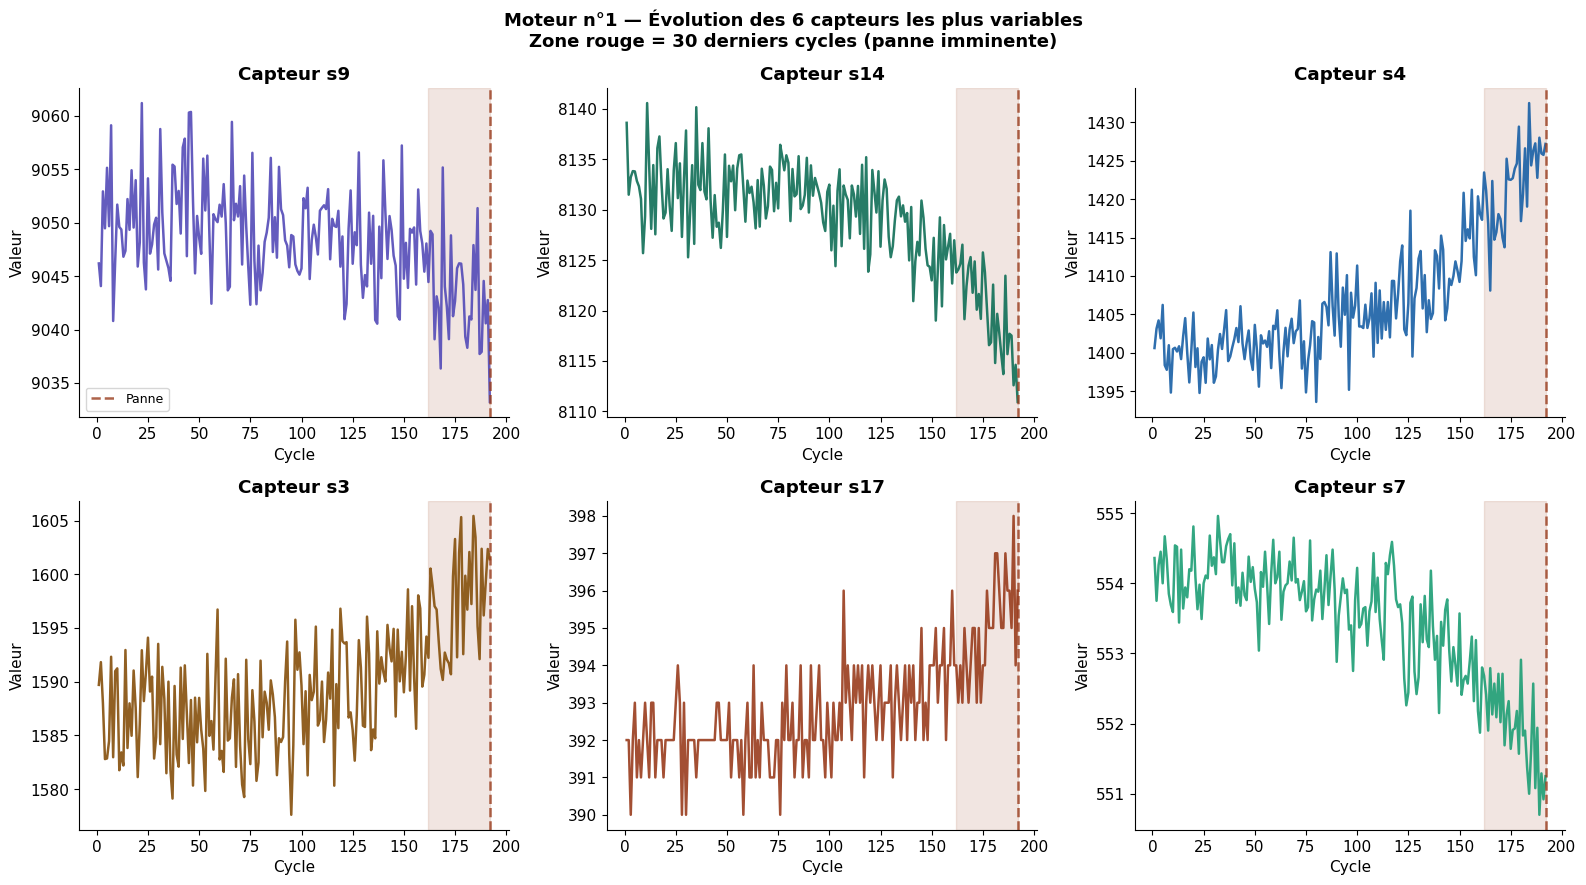

Observe : certains capteurs montent progressivement avant la panne
Ce sont ces tendances que le modèle ML va apprendre à détecter


In [9]:

# Les 6 capteurs avec la plus grande variance
top6 = std_capteurs[std_capteurs >= SEUIL_STD].sort_values(ascending=False).head(6).index.tolist()

moteur1     = df[df['unit_id'] == 1].copy()
cycle_fin   = moteur1['cycle'].max()
couleurs    = ['#534AB7','#0F6E56','#185FA5','#854F0B','#993C1D','#1D9E75']

fig, axes = plt.subplots(2, 3, figsize=(16, 9))
axes = axes.flatten()

for i, (cap, col) in enumerate(zip(top6, couleurs)):
    ax = axes[i]
    ax.plot(moteur1['cycle'], moteur1[cap], color=col, linewidth=1.8, alpha=0.9)
    ax.axvspan(cycle_fin - SEUIL_PANNE, cycle_fin, alpha=0.13, color='#993C1D')
    ax.axvline(cycle_fin, color='#993C1D', linewidth=1.8, linestyle='--', alpha=0.8, label='Panne')
    ax.set_title(f'Capteur {cap}', fontweight='bold')
    ax.set_xlabel('Cycle')
    ax.set_ylabel('Valeur')
    if i == 0: ax.legend(fontsize=9)

fig.suptitle(f'Moteur n°1 — Évolution des 6 capteurs les plus variables\n'
             f'Zone rouge = {SEUIL_PANNE} derniers cycles (panne imminente)',
             fontsize=13, fontweight='bold')
plt.tight_layout()
plt.savefig('../data/processed/g3_evolution.png', dpi=150, bbox_inches='tight')
plt.show()
print('Observe : certains capteurs montent progressivement avant la panne')
print('Ce sont ces tendances que le modèle ML va apprendre à détecter')

## Cellule 10 — Comparer normal vs panne

Est-ce que les capteurs ont des valeurs différentes selon l'état de la machine ?
C'est la question fondamentale du Machine Learning.

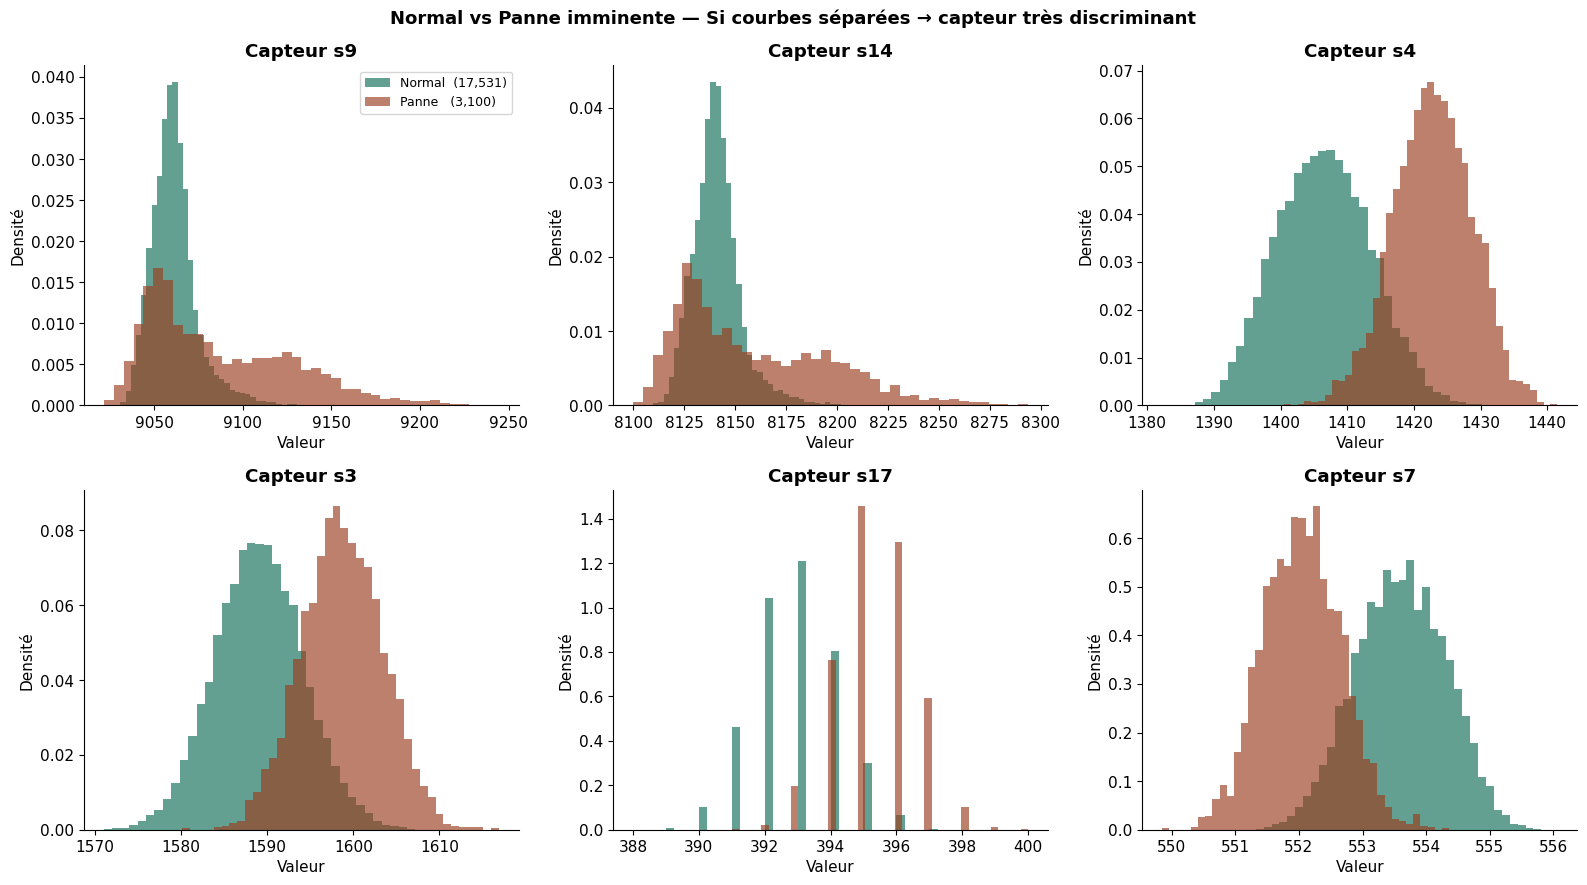

In [10]:

df_normal = df[df['label'] == 0]
df_panne  = df[df['label'] == 1]

fig, axes = plt.subplots(2, 3, figsize=(16, 9))
axes = axes.flatten()

for i, cap in enumerate(top6):
    ax = axes[i]
    ax.hist(df_normal[cap], bins=40, alpha=0.65, color='#0F6E56',
            label=f'Normal  ({len(df_normal):,})', density=True)
    ax.hist(df_panne[cap],  bins=40, alpha=0.65, color='#993C1D',
            label=f'Panne   ({len(df_panne):,})',  density=True)
    ax.set_title(f'Capteur {cap}', fontweight='bold')
    ax.set_xlabel('Valeur')
    ax.set_ylabel('Densité')
    if i == 0: ax.legend(fontsize=9)

fig.suptitle('Normal vs Panne imminente — Si courbes séparées → capteur très discriminant',
             fontsize=13, fontweight='bold')
plt.tight_layout()
plt.savefig('../data/processed/g4_normal_vs_panne.png', dpi=150, bbox_inches='tight')
plt.show()

## Cellule 11 — Corrélation des capteurs avec le RUL

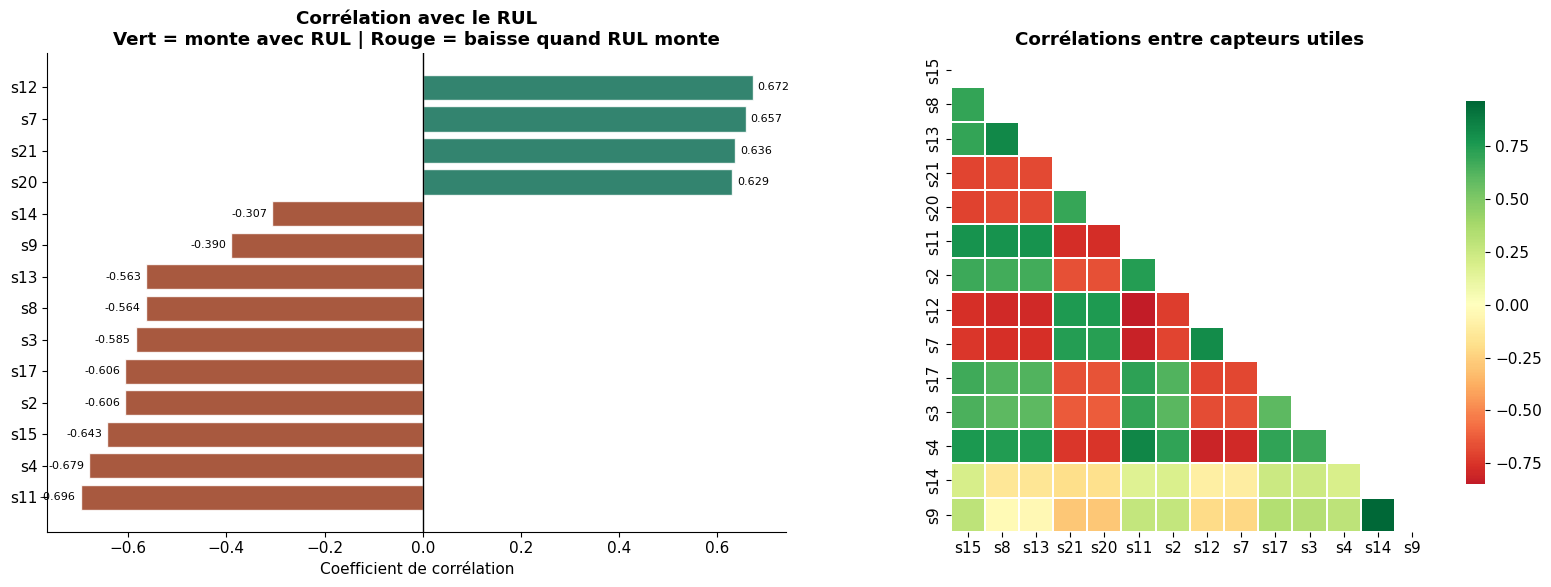

Top 3 capteurs corrélés avec RUL :
  s11 : corr=-0.696  → quand RUL baisse, s11 baisse
  s4 : corr=-0.679  → quand RUL baisse, s4 baisse
  s12 : corr=0.672  → quand RUL baisse, s12 monte


In [11]:

corr_rul = df[CAPTEURS_UTILES + ['RUL']].corr()['RUL'].drop('RUL').sort_values()

fig, axes = plt.subplots(1, 2, figsize=(16, 6))

couleurs = ['#993C1D' if v < 0 else '#0F6E56' for v in corr_rul.values]
bars = axes[0].barh(corr_rul.index, corr_rul.values, color=couleurs, alpha=0.85, edgecolor='white')
axes[0].axvline(0, color='black', linewidth=1)
axes[0].set_title('Corrélation avec le RUL\nVert = monte avec RUL | Rouge = baisse quand RUL monte', fontweight='bold')
axes[0].set_xlabel('Coefficient de corrélation')

for bar, val in zip(bars, corr_rul.values):
    axes[0].text(val + (0.01 if val >= 0 else -0.01),
                 bar.get_y() + bar.get_height()/2,
                 f'{val:.3f}', va='center',
                 ha='left' if val >= 0 else 'right', fontsize=8)

corr_mat = df[CAPTEURS_UTILES].corr()
mask = np.triu(np.ones_like(corr_mat, dtype=bool))
sns.heatmap(corr_mat, mask=mask, cmap='RdYlGn', center=0, ax=axes[1],
            square=True, annot=False, cbar_kws={'shrink':0.8}, linewidths=0.3)
axes[1].set_title('Corrélations entre capteurs utiles', fontweight='bold')

plt.tight_layout()
plt.savefig('../data/processed/g5_correlations.png', dpi=150, bbox_inches='tight')
plt.show()

#heatmap:Si 2 capteurs ont une corrélation très proche de +1.0 (vert très foncé), c'est de la redondance — ils donnent la même information. Dans ce cas tu pourrais en supprimer un

print('Top 3 capteurs corrélés avec RUL :')
for cap in corr_rul.abs().sort_values(ascending=False).head(3).index:
    direction = 'monte' if corr_rul[cap] > 0 else 'baisse'
    print(f'  {cap} : corr={corr_rul[cap]:.3f}  → quand RUL baisse, {cap} {direction}')

## Cellule 12 — Sauvegarde : dataset complet NON divisé

On sauvegarde le dataset brut avec RUL et labels.
**La division train/test se fait dans le notebook 02_preprocessing.ipynb**

In [ ]:

import json

# Sauvegarder le dataset complet (PAS de split train/test ici)
CHEMIN_SAVE = '../data/processed/dataset_explore.csv'
df.to_csv(CHEMIN_SAVE, index=False)
taille = os.path.getsize(CHEMIN_SAVE) / (1024*1024)
print(f'Dataset sauvegardé : {CHEMIN_SAVE}  ({taille:.1f} MB)')
print(f'Lignes : {len(df):,}  |  Colonnes : {len(df.columns)}')

# Sauvegarder la config pour les prochains notebooks
config = {
    'nb_lignes'         : len(df),
    'nb_moteurs'        : int(df['unit_id'].nunique()),
    'capteurs_tous'     : CAPTEURS_TOUS,
    'capteurs_utiles'   : CAPTEURS_UTILES,
    'capteurs_inutiles' : CAPTEURS_INUTILES,
    'seuil_panne'       : SEUIL_PANNE,
    'nb_label_0'        : int((df['label']==0).sum()),
    'nb_label_1'        : int((df['label']==1).sum()),
    'pct_label_1'       : round((df['label']==1).mean()*100, 2),
    'top6_capteurs'     : top6,
    'division_faite'    : False,
    'note'              : 'Division train/test à faire dans 02_preprocessing.ipynb',
}
with open('../data/processed/config_etape1.json', 'w') as f:
    json.dump(config, f, indent=2)
print('Config sauvegardée : data/processed/config_etape1.json')

print()

print('   RÉSUMÉ — ÉTAPE 1 TERMINÉE')

print(f'  Lignes totales          : {len(df):,}')
print(f'  Moteurs                 : {df["unit_id"].nunique()}')
print(f'  Capteurs utiles         : {len(CAPTEURS_UTILES)} / 21')
print(f'  Capteurs inutiles       : {len(CAPTEURS_INUTILES)} / 21 → supprimés au preprocessing')
print(f'  Label 0 (normal)        : {(df["label"]==0).sum():,} ({(df["label"]==0).mean()*100:.1f}%)')
print(f'  Label 1 (panne)         : {(df["label"]==1).sum():,} ({(df["label"]==1).mean()*100:.1f}%)')

NameError: name 'df' is not defined

: 